# 02 — Pembersihan Data
### Milestone M2 · Exploratory Data Analysis (KMTI21133)

| | |
|---|---|
| **Nama tim** | (Bakery Sales) |
| **Anggota** | Alfandi Panca Saputra (0110225026) <br>Muhammad Sultan Ridho (0110225099)<br>Dzakwan Abdur Rasyid (0110225036)<br>Mumtaaz Abdurrahman (0110225164) |
| **Topik proyek** | Eksplorasi Data Penjualan Bakery |
| **Tanggal** | 9 November 2026 |


**Notebook ini mengisi:** dimensi **Justifikasi keputusan cleaning** (30), **Ketepatan implementasi** (20), dan **Dokumentasi dan keterlacakan** (15) pada Rubrik M2.

Dimensi dengan bobot terbesar di M2 bukan kode yang benar, melainkan **alasan** di balik
setiap keputusan. Untuk setiap langkah, tuliskan tiga hal: apa yang dilakukan, mengapa,
dan apa dampaknya terhadap data.

Urutan langkah di notebook ini harus sama dengan urutan di `cleaning_log.md`.

---
> **Sebelum mengumpulkan:** jalankan **Kernel → Restart & Run All**. Notebook yang tidak dapat
> berjalan dari awal sampai akhir dianggap tidak memenuhi dimensi *ketepatan implementasi*.

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 60)
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})

DATA  = '#0E7490'   # warna utama
SOROT = '#C2410C'   # penyorot
REDUP = '#5B6672'

# Path relatif terhadap folder notebooks/ -- JANGAN diganti menjadi path absolut.
AKAR      = Path('..')
RAW       = AKAR / 'data' / 'raw'
PROCESSED = AKAR / 'data' / 'processed'
FIGURES   = AKAR / 'reports' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

## 0. Muat ulang data mentah

Selalu mulai dari `data/raw`, bukan dari hasil pembersihan sebelumnya. Dengan begitu
notebook ini dapat dijalankan ulang kapan saja dan memberi hasil yang sama.

In [7]:
BERKAS = '/content/drive/MyDrive/Proyek Tim/data/raw/Bakery sales (2).csv'

try:
    df_raw = pd.read_csv(BERKAS)
    df = df_raw.copy()
    print(f'baris awal: {len(df_raw)}')
except FileNotFoundError:
    print(f"[ERROR] Berkas tidak ditemukan di jalur: {BERKAS}")
    print("Silakan periksa kembali apakah Google Drive sudah di-mount atau ganti variabel BERKAS dengan jalur yang benar.")

log = []
def catat(langkah, alasan, sebelum, sesudah):
    log.append({'langkah': langkah, 'alasan': alasan,
                'baris_sebelum': sebelum, 'baris_sesudah': sesudah,
                'selisih': sesudah - sebelum})
    print(f'[{len(log):02d}] {langkah}: {sebelum} -> {sesudah} baris ({sesudah-sebelum:+d})')

baris awal: 234005


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Langkah 1 — Buang kolom `Unnamed: 0`

**Apa:** Menghapus kolom `Unnamed: 0` dari data.
**Mengapa:** Kolom ini adalah indeks baris bawaan file CSV (sisa `to_csv` tanpa `index=False`). Isinya hanya nomor urut, tidak membawa informasi bisnis, dan bila dibiarkan bisa terbaca sebagai fitur numerik pada analisis berikutnya.
**Alternatif yang dipertimbangkan:** Menjadikannya indeks DataFrame (`index_col=0`). Tidak dipilih karena nomor urut dari file sumber tidak memiliki arti, dan pandas sudah membuat indeksnya sendiri. Jumlah baris tidak berubah.

In [8]:
n0 = len(df)

df = df.drop(columns=['Unnamed: 0'], errors='ignore')
catat('Drop kolom index berlebih', 'Kolom ini duplikasi index pandas', n0, len(df))

[01] Drop kolom index berlebih: 234005 -> 234005 baris (+0)


## Langkah 2 — Ubah `unit_price` menjadi numerik

**Apa:** Menghilangkan simbol `€`, mengganti koma desimal dengan titik, lalu mengonversi ke `float`.
**Mengapa:** Di file mentah harga tersimpan sebagai teks berformat Eropa (mis. `0,90 €`). Selama masih teks, harga tidak bisa dikalikan dengan `Quantity` untuk menghitung pendapatan, dan statistik deskriptif tidak bisa dihitung.
**Alternatif yang dipertimbangkan:** Membaca ulang dengan `pd.read_csv(..., decimal=',')`. Tidak cukup karena simbol `€` tetap ada. `pd.to_numeric` dibiarkan **tanpa** `errors='coerce'` agar bila ada format tak terduga, notebook berhenti dan tidak diam-diam menghasilkan `NaN`.

In [9]:
n0 = len(df)
print('contoh sebelum:', df['unit_price'].head(3).tolist())
df['unit_price'] = (df['unit_price'].astype(str)
                    .str.replace('€', '', regex=False)
                    .str.replace(',', '.', regex=False)
                    .str.strip())
df['unit_price'] = pd.to_numeric(df['unit_price'])
print('contoh sesudah:', df['unit_price'].head(3).tolist())
catat('Konversi unit_price', 'Agar bisa dikalkulasi menjadi total penjualan', n0, len(df))

contoh sebelum: ['0,90 €', '1,20 €', '1,20 €']
contoh sesudah: [0.9, 1.2, 1.2]
[02] Konversi unit_price: 234005 -> 234005 baris (+0)


## Langkah 3 — Buang `Quantity` ≤ 0 (retur/pembatalan)

**Apa:** Menyaring baris dengan `Quantity > 0`.
**Mengapa:** Nilai negatif atau nol bukan penjualan, melainkan retur, pembatalan, atau koreksi kasir. Jika dibiarkan, total penjualan akan terpotong dan tren penjualan harian menjadi bias. Topik proyek ini adalah pola penjualan normal, sehingga transaksi non-penjualan dikeluarkan.
**Alternatif yang dipertimbangkan:** (a) Mempertahankan nilai negatif untuk menghitung *net sales*. Tidak dipilih karena tidak ada ID yang mengaitkan retur ke transaksi aslinya sehingga net sales tidak bisa dihitung dengan benar. (b) Mengubah ke nilai mutlak. Ditolak karena akan mengarang penjualan yang tidak terjadi.

In [10]:
n0 = len(df)
print('Quantity <= 0:', (df['Quantity'] <= 0).sum(), '| contoh nilai:', sorted(df.loc[df['Quantity'] <= 0, 'Quantity'].unique())[:10])
df = df[df['Quantity'] > 0].copy()
catat('Buang retur/batal', 'Nilai kuantitas <= 0 adalah retur/kesalahan, tidak relevan untuk analisis tren penjualan normal', n0, len(df))

Quantity <= 0: 1295 | contoh nilai: [np.float64(-200.0), np.float64(-18.0), np.float64(-17.0), np.float64(-13.0), np.float64(-12.0), np.float64(-10.0), np.float64(-9.0), np.float64(-8.0), np.float64(-7.0), np.float64(-6.0)]
[03] Buang retur/batal: 234005 -> 232710 baris (-1295)


**Bukti dampak:** distribusi `Quantity` sebelum dan sesudah, dengan sumbu dan lebar bin yang identik.

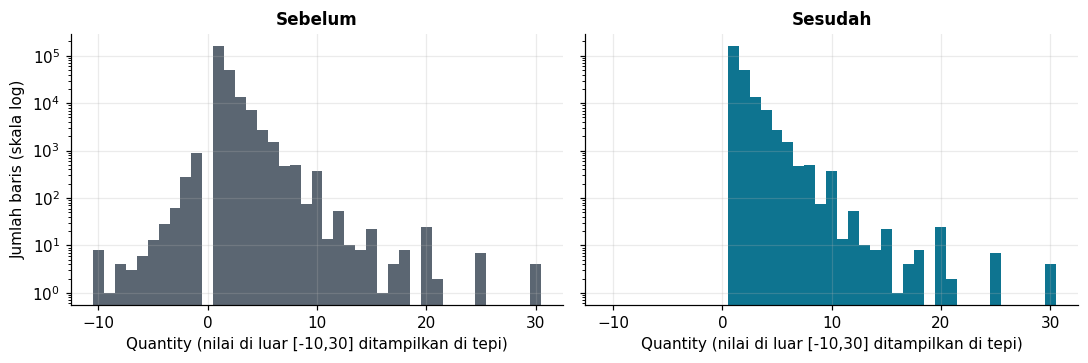

Quantity min sebelum: -200.0 | sesudah: 1.0


In [11]:
LO, HI = -10, 30
bins = np.arange(LO - 0.5, HI + 1.5, 1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True, sharey=True)
ax[0].hist(df_raw['Quantity'].clip(LO, HI), bins=bins, color=REDUP); ax[0].set_title('Sebelum')
ax[1].hist(df['Quantity'].clip(LO, HI),     bins=bins, color=DATA);  ax[1].set_title('Sesudah')
for a in ax: a.set_xlabel(f'Quantity (nilai di luar [{LO},{HI}] ditampilkan di tepi)'); a.set_yscale('log')
ax[0].set_ylabel('Jumlah baris (skala log)')
plt.tight_layout()
plt.savefig(FIGURES / 'cleaning_quantity_sebelum_sesudah.png', bbox_inches='tight')
plt.show()
print('Quantity min sebelum:', df_raw['Quantity'].min(), '| sesudah:', df['Quantity'].min())

## Langkah 4 — Buang baris duplikat persis

**Apa:** Menghapus baris yang identik di semua kolom (`date`, `time`, `ticket_number`, `article`, `Quantity`, `unit_price`).
**Mengapa:** Dalam data ini satu baris mewakili satu jenis produk pada satu tiket, dengan jumlahnya sudah dirangkum di `Quantity`. Dua baris yang identik penuh (tiket, menit, produk, jumlah, harga sama) paling masuk akal dibaca sebagai entri ganda, sehingga menghitungnya dua kali menggelembungkan pendapatan. **Ini adalah asumsi**; jumlah baris yang terdampak dilaporkan di bawah agar dampaknya dapat dinilai.
**Alternatif yang dipertimbangkan:** Mempertahankan semua baris dengan anggapan kasir memindai produk yang sama dua kali. Tidak dipilih karena `Quantity` sudah menampung kasus itu.

In [12]:
n0 = len(df)
dup = df.duplicated().sum()
print(f'baris duplikat persis: {dup} ({dup/n0*100:.2f}%)')
df = df.drop_duplicates().copy()
catat('Buang duplikat persis', 'Satu baris = satu produk per tiket; baris identik penuh dianggap entri ganda', n0, len(df))

baris duplikat persis: 1199 (0.52%)
[04] Buang duplikat persis: 232710 -> 231511 baris (-1199)


## Langkah 5 — Tambah `total_sales` dan `datetime`

**Apa:** Membuat `total_sales = Quantity × unit_price` dan menggabungkan `date` + `time` menjadi satu kolom `datetime` bertipe waktu.
**Mengapa:** `total_sales` adalah ukuran pendapatan yang menjadi inti analisis. `datetime` diperlukan untuk analisis deret waktu (jam sibuk, tren harian/bulanan) tanpa harus menggabungkan kolom berulang kali.
**Alternatif yang dipertimbangkan:** Menunda pembuatan fitur ke notebook EDA. Dipilih dilakukan di sini agar seluruh turunan terdokumentasi di satu tempat dan konsisten. Kolom `date` dan `time` asli dipertahankan.

In [13]:
n0 = len(df)
df['total_sales'] = df['Quantity'] * df['unit_price']
df['datetime'] = pd.to_datetime(df['date'] + ' ' + df['time'])
print('rentang waktu:', df['datetime'].min(), 's.d.', df['datetime'].max())
catat('Tambah fitur turunan', 'Untuk time-series dan visualisasi tren revenue', n0, len(df))

rentang waktu: 2021-01-02 08:38:00 s.d. 2022-09-30 18:56:00
[05] Tambah fitur turunan: 231511 -> 231511 baris (+0)


## Penanganan nilai yang hilang

Keputusan ini dinilai paling ketat. Pemeriksaan dilakukan pada data **setelah** langkah 1–5, karena konversi tipe (mis. `to_numeric`, `to_datetime`) bisa memunculkan `NaN` baru bila ada format yang rusak.

| Mekanisme | Artinya | Penanganan yang biasanya sesuai |
|---|---|---|
| MCAR | kekosongan acak sepenuhnya | boleh dibuang; bias kecil |
| MAR | kekosongan dijelaskan kolom lain yang teramati | imputasi dengan prediktor, atau analisis terpisah |
| MNAR | kekosongan bergantung pada nilai yang tidak terlihat | **jangan** diisi rata-rata; laporkan dan batasi klaim |

**Keputusan:** Tidak melakukan imputasi apa pun. Seluruh kolom adalah catatan transaksi mesin kasir (tanggal, jam, tiket, produk, jumlah, harga), sehingga nilai kosong bila ada bukan sesuatu yang bisa "ditebak" secara wajar. Mengisi harga atau jumlah dengan rata-rata akan memalsukan pendapatan. Jika ditemukan baris kosong, baris tersebut dibuang (asumsi MCAR, dilaporkan jumlahnya); bila tidak ada, ini dicatat sebagai hasil pemeriksaan, bukan kelalaian. Asumsi MCAR tidak dapat dibuktikan dari data saja.

In [14]:
kosong = df.isna().sum()
print(kosong.to_string())
print('\ntotal sel kosong:', int(kosong.sum()))

n0 = len(df)
if kosong.sum() > 0:
    df = df.dropna().copy()
    catat('Buang baris dengan nilai kosong', 'Data transaksi tidak layak diimputasi; asumsi MCAR', n0, len(df))
else:
    print('Tidak ada nilai kosong -> tidak ada tindakan (keputusan sadar).')

date             0
time             0
ticket_number    0
article          0
Quantity         0
unit_price       0
total_sales      0
datetime         0

total sel kosong: 0
Tidak ada nilai kosong -> tidak ada tindakan (keputusan sadar).


## Penanganan data pribadi

Wajib dilakukan **sebelum** data disimpan ke `data/processed`.

Dataset ini tidak memuat nama atau identitas pelanggan. Satu-satunya pengenal adalah `ticket_number` (nomor struk). Nomor ini tidak langsung mengidentifikasi orang, tetapi dapat dipakai menelusuri kembali ke struk asli, sehingga disamarkan dengan hash satu arah (SHA-256, 12 karakter pertama). Hash bersifat deterministik: baris dari tiket yang sama tetap punya kode yang sama, sehingga analisis "isi keranjang per tiket" tetap bisa dilakukan.
**Alternatif:** menghapus kolomnya. Tidak dipilih karena akan menghilangkan kemampuan mengelompokkan item per transaksi.

In [16]:
import hashlib

def samarkan(s):
    """Hash satu arah; nilai asli tidak dapat dikembalikan."""
    return hashlib.sha256(str(s).encode()).hexdigest()[:12]

n_tiket_asli = df['ticket_number'].nunique()
df['ticket_number'] = df['ticket_number'].map(samarkan)

# Verifikasi: jumlah tiket unik tidak berubah (tidak ada tabrakan hash) dan tidak ada kolom pengenal lain
assert df['ticket_number'].nunique() == n_tiket_asli, 'terjadi tabrakan hash pada ticket_number'
print(df.columns.tolist())
print(df['ticket_number'].head(3).tolist())

['date', 'time', 'ticket_number', 'article', 'Quantity', 'unit_price', 'total_sales', 'datetime']
['fc5df6b61429', 'fc5df6b61429', '4e71d9986966']


## Validasi akhir

Tuliskan sebagai `assert`. Bila suatu saat data atau kode berubah dan hasilnya rusak,
notebook akan berhenti di sini — bukan diam-diam menghasilkan angka yang salah.

In [17]:
assert df.duplicated().sum() == 0, 'masih ada baris kembar'
assert (df['Quantity'] > 0).all(), 'masih ada kuantitas <= 0'
assert pd.api.types.is_numeric_dtype(df['unit_price']), 'unit_price bukan numerik'
assert pd.api.types.is_datetime64_any_dtype(df['datetime']), 'datetime bukan tipe waktu'
assert df.isna().sum().sum() == 0, 'masih ada nilai kosong'
assert np.allclose(df['total_sales'], df['Quantity'] * df['unit_price']), 'total_sales tidak konsisten'
assert 'Unnamed: 0' not in df.columns, 'kolom index masih ada'
assert df['ticket_number'].str.len().eq(12).all(), 'ticket_number belum disamarkan'

print(f'LOLOS. {len(df)} baris x {df.shape[1]} kolom siap dianalisis.')

LOLOS. 231511 baris x 8 kolom siap dianalisis.


## Simpan hasil

In [ ]:
PROCESSED.mkdir(parents=True, exist_ok=True)
KELUARAN = PROCESSED / 'data_bersih.csv'
df.to_csv(KELUARAN, index=False)
print('tersimpan:', KELUARAN.resolve())

ringkas = pd.DataFrame(log)
print()
print(ringkas.to_string(index=False))
print()
print(f'Total: {len(df_raw)} -> {len(df)} baris '
      f'({(len(df)-len(df_raw))/len(df_raw)*100:+.1f}%)')

In [ ]:
# Salin keluaran sel ini ke cleaning_log.md
baris = ['# Cleaning Log', '',
         f'Sumber   : `{BERKAS.name}` ({len(df_raw)} baris)',
         f'Keluaran : `{KELUARAN.name}` ({len(df)} baris)', '',
         '| # | Langkah | Alasan | Baris sebelum | Baris sesudah |',
         '|---|---------|--------|---------------|---------------|']
for i, r in enumerate(log, 1):
    baris.append(f"| {i} | {r['langkah']} | {r['alasan']} | {r['baris_sebelum']} | {r['baris_sesudah']} |")
print('\n'.join(baris))

## Checklist sebelum mengumpulkan

- [x] Setiap langkah memiliki **apa**, **mengapa**, dan **alternatif yang dipertimbangkan**.
- [x] Minimal satu langkah disertai bukti dampak berupa perbandingan sebelum–sesudah (Langkah 3).
- [x] Panel sebelum–sesudah memakai sumbu dan lebar bin yang identik.
- [x] Penanganan nilai hilang didasarkan pada mekanismenya, bukan kemudahan.
- [x] Data pribadi sudah ditangani **dan** diverifikasi.
- [x] Ada blok `assert` validasi akhir.
- [ ] `cleaning_log.md` sudah diperbarui dari keluaran sel terakhir.
- [x] `data/raw` tidak berubah (`df_raw` hanya dibaca, perubahan pada salinan).